<center><h1>Case_John_HW5</h1></center>
<br>
<br>

Name: John Case
<br>
Github Username: johncase17
<br>
USC ID: 2249212508

## 1. Decision Trees as Interpretable Models

Import packages

In [110]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import plot_tree
%pip install -r ../requirements.txt

import pandas as pd
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.tree import export_text
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### (a) Obtain Data

Get the Accute Inamations Data Set

In [81]:
diagnosis_path = '../data/diagnosis.csv'
features_names = ['temp', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pain', 'urethra_discomfort']
accute_data = pd.read_csv(diagnosis_path, sep='\t', decimal=',', encoding='utf-16', header=None)
accute_data = accute_data.replace({'no': 0, 'yes': 1})
accute_data[0] = accute_data[0].astype(float)
for col in accute_data.columns:
    if col >= 1:
        accute_data[col] = accute_data[col].astype(int)


inflamation = accute_data[6].copy()
nephriti = accute_data[7].copy()
combined_predict = ["empty"]*len(accute_data)
for i in range(len(inflamation)):
    if inflamation[i] == 1 and nephriti[i] == 1:
        combined_predict[i] = "inflamation and nephriti"
    elif inflamation[i] == 1 and nephriti[i] == 0:
        combined_predict[i] = "inflamation"
    elif inflamation[i] == 0 and nephriti[i] == 1:
        combined_predict[i] = "nephriti"
    else:
        combined_predict[i] = "none"
accute_data = accute_data.drop(accute_data.columns[[6, 7]], axis=1)
accute_data.columns = features_names
#print(accute_data.head())
#print(combined_predict)


### (b) Build a decision tree

['inflamation' 'inflamation and nephriti' 'nephriti' 'none']


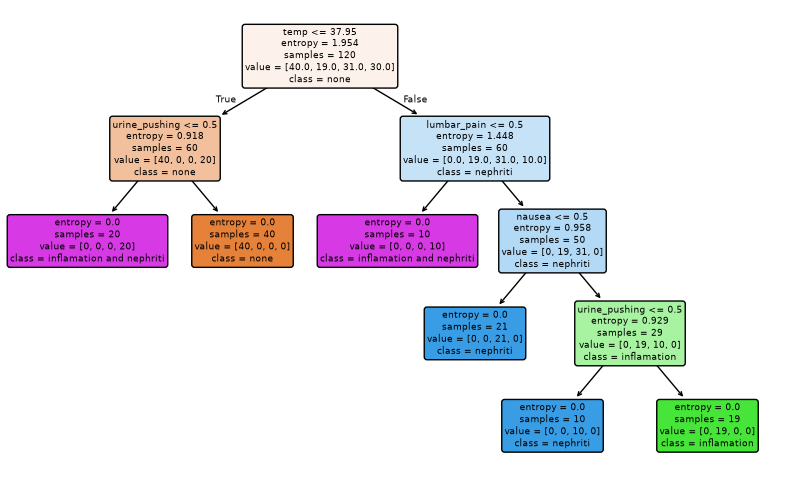

In [87]:
inflamation_dt = tree.DecisionTreeClassifier(criterion='entropy', max_depth=5)
inflamation_dt.fit(accute_data, combined_predict)
print(inflamation_dt.classes_)
plt.figure(figsize=(10, 6))
names = list(dict.fromkeys(combined_predict))
plot_tree(inflamation_dt, filled=True, rounded=True, feature_names=features_names, class_names=names)
plt.show()

### (c) Convert the decision rules

In [108]:
#Snippet taken from https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html
def tree_to_code(tree, feature_names):
	"""
	Outputs a decision tree model as a Python function

	Parameters:
	-----------
	tree: decision tree model
		The decision tree to represent as a function
	feature_names: list
		The feature names of the dataset used for building the decision tree
	"""

	tree_ = tree.tree_
	feature_name = feature_names
	print("def tree({}):".format(", ".join(feature_names)))

	def recurse(node, depth):
		indent = "  " * depth
		if tree_.feature[node] != -2:
			name = feature_names[tree_.feature[node]]
			threshold = tree_.threshold[node]
			print("{}if {} <= {}:".format(indent, name, threshold))
			recurse(tree_.children_left[node], depth + 1)
			print("{}else:  # if {} > {}".format(indent, name, threshold))
			recurse(tree_.children_right[node], depth + 1)
		else:
			print("{}return {}".format(indent, tree.classes_[tree_.value[node].argmax()]))

	recurse(0, 1)

tree_to_code(inflamation_dt, features_names)

def tree(temp, nausea, lumbar_pain, urine_pushing, micturition_pain, urethra_discomfort):
  if temp <= 37.95000076293945:
    if urine_pushing <= 0.5:
      return none
    else:  # if urine_pushing > 0.5
      return inflamation
  else:  # if temp > 37.95000076293945
    if lumbar_pain <= 0.5:
      return none
    else:  # if lumbar_pain > 0.5
      if nausea <= 0.5:
        return nephriti
      else:  # if nausea > 0.5
        if urine_pushing <= 0.5:
          return nephriti
        else:  # if urine_pushing > 0.5
          return inflamation and nephriti


### (d) Minimal decision tree

5


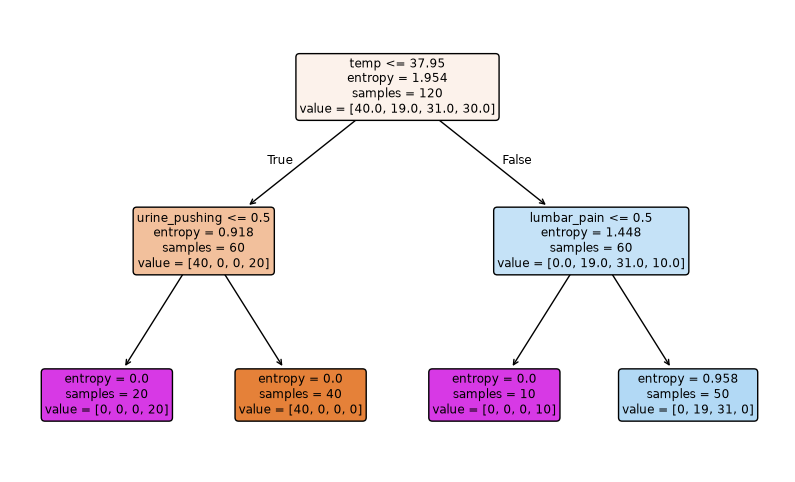

def tree(temp, nausea, lumbar_pain, urine_pushing, micturition_pain, urethra_discomfort):
  if temp <= 37.95000076293945:
    if urine_pushing <= 0.5:
      return none
    else:  # if urine_pushing > 0.5
      return inflamation
  else:  # if temp > 37.95000076293945
    if lumbar_pain <= 0.5:
      return none
    else:  # if lumbar_pain > 0.5
      return nephriti


In [132]:
#reference: https://www.geeksforgeeks.org/machine-learning/pruning-decision-trees/
parameters = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'splitter': ['best', 'random'],
    'max_depth': [1, 2, 3, 4, 5],
    'max_features': ['sqrt', 'log2']
}
tree = DecisionTreeClassifier()
validation = GridSearchCV(estimator=tree, param_grid=parameters)
path = inflamation_dt.cost_complexity_pruning_path(accute_data, combined_predict)
ccp_alphas = path.ccp_alphas
results = []

for value in ccp_alphas:
    temp_model = DecisionTreeClassifier(criterion='entropy', ccp_alpha=value, random_state=42)
    temp_model.fit(accute_data, combined_predict)
    results.append(temp_model)

best_combo = results[0]
for model in results:
    accuracy = model.score(accute_data, combined_predict)
    if accuracy >= 0.8:
        if model.get_depth() < best_combo.get_depth():
            best_combo = model
print(len(ccp_alphas))
plt.figure(figsize=(10, 6))
plot_tree(best_combo, filled=True, rounded=True, feature_names=features_names)
plt.show()
tree_to_code(best_combo, features_names)


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [143]:
communities_path = '../data/communities.csv'
communities_headers = pd.read_csv('../data/communities_headers.csv').columns
communities_data = pd.read_csv(communities_path, na_values='?', header=None)
communities_data.columns = communities_headers
print(communities_data.shape)

(1994, 128)


### (b) Missing values

### (c) Plot a correlation matrix

### (d) Calculate the Coefficient of Variation CV

### (e) Scatter plots and box plots for highest CV features

### (f) Fit a linear model

### (g) Fit a ridge regression model

### (h) Fit a LASSO model

### (i) Fit a PCR model

### (j) Fit a boosting tree